# Small encoder-decoder CNN

This notebook reads the fixed split, trains the small RGB semantic-segmentation CNN, and saves the best model and training history.

In [1]:
from pathlib import Path
import json
import math
import random
import numpy as np
from PIL import Image
import tensorflow as tf

# Run in a fresh kernel before TensorFlow initializes any devices.
tf.config.set_visible_devices([], 'GPU')
print('CNN training device: CPU')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
PATCH_SIZE = 256
BATCH_SIZE = 8
IGNORE_LABEL = 255
NUM_CLASSES = 3
CLASS_COLORS = np.array([[199, 199, 199], [31, 119, 180], [255, 127, 14]], dtype=np.uint8)
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'project_plan.md').exists():
    PROJECT_ROOT = PROJECT_ROOT / 'final-project'
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts'
FIGURE_DIR = ARTIFACT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
split_record = json.loads((ARTIFACT_DIR / 'split.json').read_text(encoding='utf-8'))
train_images = [PROJECT_ROOT / p for p in split_record['train_images']]
val_images = [PROJECT_ROOT / p for p in split_record['validation_images']]
def mask_for(path): return path.parent.parent / 'msk' / f'{path.stem}.png'
train_masks = [mask_for(p) for p in train_images]
val_masks = [mask_for(p) for p in val_images]
print('Training sources:', len(train_images), 'Validation sources:', len(val_images))


CNN training device: CPU
Training sources: 9 Validation sources: 3


In [2]:
def generate_patches(image_paths, mask_paths):
    for image_path, mask_path in zip(image_paths, mask_paths):
        with Image.open(image_path) as image, Image.open(mask_path) as mask:
            rgb = np.asarray(image.convert('RGB'))
            mask_rgb = np.asarray(mask.convert('RGB'))
        labels = np.full(mask_rgb.shape[:2], IGNORE_LABEL, dtype=np.uint8)
        for class_id, color in enumerate(CLASS_COLORS):
            labels[np.all(mask_rgb == color, axis=-1)] = class_id
        for y in range(0, labels.shape[0], PATCH_SIZE):
            for x in range(0, labels.shape[1], PATCH_SIZE):
                height, width = min(PATCH_SIZE, labels.shape[0] - y), min(PATCH_SIZE, labels.shape[1] - x)
                image_patch = np.zeros((PATCH_SIZE, PATCH_SIZE, 3), dtype=np.float32)
                label_patch = np.full((PATCH_SIZE, PATCH_SIZE), IGNORE_LABEL, dtype=np.int32)
                weight_patch = np.zeros((PATCH_SIZE, PATCH_SIZE), dtype=np.float32)
                image_patch[:height, :width] = rgb[y:y + height, x:x + width] / 255.0
                label_patch[:height, :width] = labels[y:y + height, x:x + width]
                weight_patch[:height, :width] = (label_patch[:height, :width] != IGNORE_LABEL).astype(np.float32)
                safe_labels = np.where(weight_patch > 0, label_patch, 0).astype(np.int32)
                yield image_patch, safe_labels, weight_patch

def make_dataset(image_paths, mask_paths, training=False):
    dataset = tf.data.Dataset.from_generator(lambda: generate_patches(image_paths, mask_paths), output_signature=(tf.TensorSpec((PATCH_SIZE, PATCH_SIZE, 3), tf.float32), tf.TensorSpec((PATCH_SIZE, PATCH_SIZE), tf.int32), tf.TensorSpec((PATCH_SIZE, PATCH_SIZE), tf.float32)))
    if training: dataset = dataset.shuffle(64, seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE)

def count_patches(paths):
    total = 0
    for path in paths:
        with Image.open(path) as image: total += math.ceil(image.height / PATCH_SIZE) * math.ceil(image.width / PATCH_SIZE)
    return total

train_steps = math.ceil(count_patches(train_images) / BATCH_SIZE)
val_steps = math.ceil(count_patches(val_images) / BATCH_SIZE)
train_dataset = make_dataset(train_images, train_masks, training=True).apply(tf.data.experimental.assert_cardinality(train_steps))
val_dataset = make_dataset(val_images, val_masks).apply(tf.data.experimental.assert_cardinality(val_steps))
print('Training steps:', train_steps, 'Validation steps:', val_steps)


Training steps: 372 Validation steps: 124


In [3]:
def convolution_block(inputs, filters, name):
    x = tf.keras.layers.Conv2D(filters, 3, padding='same', activation='relu', name=f'{name}_conv1')(inputs)
    return tf.keras.layers.Conv2D(filters, 3, padding='same', activation='relu', name=f'{name}_conv2')(x)

def build_small_encoder_decoder():
    inputs = tf.keras.Input((PATCH_SIZE, PATCH_SIZE, 3), name='rgb_input')
    encoder_1 = convolution_block(inputs, 16, 'encoder_1')
    encoder_2 = convolution_block(tf.keras.layers.MaxPooling2D(2)(encoder_1), 32, 'encoder_2')
    bottleneck = convolution_block(tf.keras.layers.MaxPooling2D(2)(encoder_2), 64, 'bottleneck')
    bottleneck = tf.keras.layers.SpatialDropout2D(0.2, name='bottleneck_dropout')(bottleneck)
    decoder_1 = convolution_block(tf.keras.layers.Concatenate()([tf.keras.layers.UpSampling2D(2)(bottleneck), encoder_2]), 32, 'decoder_1')
    decoder_2 = convolution_block(tf.keras.layers.Concatenate()([tf.keras.layers.UpSampling2D(2)(decoder_1), encoder_1]), 16, 'decoder_2')
    outputs = tf.keras.layers.Conv2D(NUM_CLASSES, 1, padding='same', activation='softmax')(decoder_2)
    return tf.keras.Model(inputs, outputs, name='small_encoder_decoder')

model = build_small_encoder_decoder()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=tf.keras.losses.SparseCategoricalCrossentropy())
model.summary()


Model: "small_encoder_decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_input           │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1_conv1     │ (None, 256, 256,  │        448 │ rgb_input[0][0]   │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1_conv2     │ (None, 256, 256,  │      2,320 │ encoder_1_conv1[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ encoder_1_conv2[… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_2_conv1     │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_2_conv2     │ (None, 128, 128,  │      9,248 │ encoder_2_conv1[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ encoder_2_conv2[… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv1    │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv2    │ (None, 64, 64,    │     36,928 │ bottleneck_conv1… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_dropout  │ (None, 64, 64,    │          0 │ bottleneck_conv2… │
│ (SpatialDropout2D)  │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 128, 128,  │          0 │ bottleneck_dropo… │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128,  │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 96)               │            │ encoder_2_conv2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_1_conv1     │ (None, 128, 128,  │     27,680 │ concatenate[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_1_conv2     │ (None, 128, 128,  │      9,248 │ decoder_1_conv1[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 256, 256,  │          0 │ decoder_1_conv2[… │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256, 256,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 48)               │            │ encoder_1_conv2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_2_conv1     │ (None, 256, 256,  │      6,928 │ concatenate_1[0]

 Total params: 118,307 (462.14 KB)

 Trainable params: 118,307 (462.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - loss: 0.0737
Epoch 1: val_loss improved from None to 0.03573, saving model to /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/small_encoder_decoder_best.keras

Epoch 1: finished saving model to /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/small_encoder_decoder_best.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 128s 341ms/step - loss: 0.0737 - val_loss: 0.0357
Epoch 2/30
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - loss: 0.0232
Epoch 2: val_loss improved from 0.03573 to 0.03288, saving model to /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/small_encoder_decoder_best.keras

Epoch 2: finished saving model to /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/small_encoder_decoder_best.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 126s 337ms/step - loss: 0.0232 - val_loss: 0.0329
Epoch 3/30
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - loss: 0.0257
Epoch 3: val_loss improved from 0.03

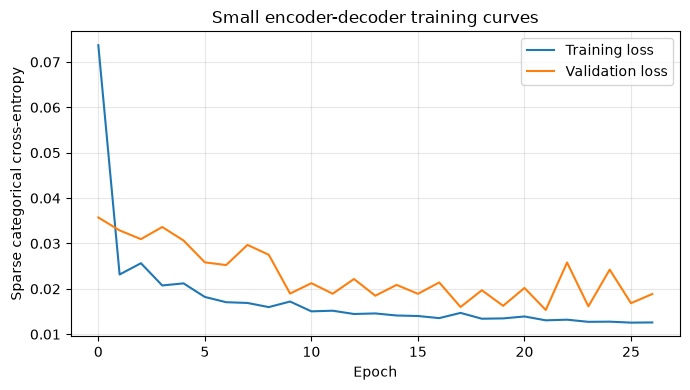

In [4]:
MAX_EPOCHS = 30
CHECKPOINT_PATH = ARTIFACT_DIR / 'small_encoder_decoder_best.keras'
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, mode='min', restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(CHECKPOINT_PATH, monitor='val_loss', mode='min', save_best_only=True, verbose=1),
]
history = model.fit(train_dataset, validation_data=val_dataset, epochs=MAX_EPOCHS, callbacks=callbacks, shuffle=False)
history_values = {key: [float(value) for value in values] for key, values in history.history.items()}
(ARTIFACT_DIR / 'small_encoder_decoder_history.json').write_text(json.dumps(history_values, indent=2) + '\n', encoding='utf-8')
figure, axis = __import__('matplotlib.pyplot').pyplot.subplots(figsize=(7, 4))
axis.plot(history_values['loss'], label='Training loss')
axis.plot(history_values['val_loss'], label='Validation loss')
axis.set(xlabel='Epoch', ylabel='Sparse categorical cross-entropy', title='Small encoder-decoder training curves')
axis.legend(); axis.grid(alpha=0.3); figure.tight_layout()
figure.savefig(FIGURE_DIR / 'small_encoder_decoder_curves.png', dpi=150)
print('Saved:', CHECKPOINT_PATH)


In [5]:
evaluation_model = tf.keras.models.load_model(
    ARTIFACT_DIR / 'small_encoder_decoder_best.keras', compile=False)
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
for images, labels, weights in val_dataset:
    prediction = np.argmax(evaluation_model(images, training=False).numpy(), axis=-1)
    valid = weights.numpy() > 0
    encoded = NUM_CLASSES * labels.numpy()[valid] + prediction[valid]
    confusion += np.bincount(encoded, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
tp = np.diag(confusion).astype(np.float64)
actual, predicted = confusion.sum(axis=1), confusion.sum(axis=0)
union = actual + predicted - tp
iou = np.divide(tp, union, out=np.zeros(NUM_CLASSES), where=union > 0)
dice = np.divide(2 * tp, actual + predicted, out=np.zeros(NUM_CLASSES), where=(actual + predicted) > 0)
cnn_scores = {
    'cnn_mean_iou': float(iou.mean()), 'cnn_weed_iou': float(iou[2]),
    'cnn_mean_dice': float(dice.mean()), 'iou': iou.tolist(), 'dice': dice.tolist(),
    'confusion_matrix': confusion.tolist(),
    'checkpoint': 'small_encoder_decoder_best.keras',
    'split': 'validation',
}
(ARTIFACT_DIR / 'CNN_VALIDATION_SCORES.json').write_text(
    json.dumps(cnn_scores, indent=2) + '\n', encoding='utf-8')
print(json.dumps(cnn_scores, indent=2))


{
  "cnn_mean_iou": 0.8373537498710172,
  "cnn_weed_iou": 0.7221022328997742,
  "cnn_mean_dice": 0.907308427080067,
  "iou": [
    0.9947090622075806,
    0.795249954505697,
    0.7221022328997742
  ],
  "dice": [
    0.9973475140346714,
    0.8859490039365139,
    0.8386287632690158
  ],
  "confusion_matrix": [
    [
      57933319,
      96779,
      48559
    ],
    [
      104045,
      1083773,
      39806
    ],
    [
      58769,
      38405,
      482113
    ]
  ],
  "checkpoint": "small_encoder_decoder_best.keras",
  "split": "validation"
}


2026-10-11 11:55:18.291270: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
